# Modern External Dataset
## Seven-Model Comparison

**Goal:** Compare the external evaluation results of seven text classifiers on the same 600 modern responses: 150 human-written responses and 150 each from ChatGPT, Claude, and Gemini.

The seven classifiers include:

- Three TF-IDF classifiers
- Three sentence-transformer embedding classifiers
- One fine-tuned RoBERTa classifier

### Evaluation Sources

This notebook combines saved CSV exports from:

- `tfidf_external_evaluation.ipynb`
- `embeddings_external_evaluation.ipynb`
- `roberta_external_evaluation.ipynb`

The fine-tuned RoBERTa checkpoint is hosted at [akeight/spot-the-bot-roberta](https://huggingface.co/akeight/spot-the-bot-roberta).

**No model training or inference is performed in this notebook.** It uses previously generated evaluation results.

The modern dataset serves as an external benchmark for assessing model generalization. Results should be interpreted rather than used repeatedly to optimize models or select thresholds.

## 1. Imports and paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents]
                     if (p / 'models').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter from inside the Spot-the-Bot repository.')
RESULTS_DIR = PROJECT_ROOT / 'data' / 'evaluation'

files = {
    'TF-IDF metrics': RESULTS_DIR / 'modern_tfidf_metrics.csv',
    'Embeddings metrics': RESULTS_DIR / 'modern_embeddings_metrics.csv',
    'TF-IDF predictions': RESULTS_DIR / 'modern_tfidf_predictions.csv',
    'Embeddings predictions': RESULTS_DIR / 'modern_embeddings_predictions.csv',
    'TF-IDF generator metrics': RESULTS_DIR / 'modern_tfidf_generator_metrics.csv',
    'Embeddings generator metrics': RESULTS_DIR / 'modern_embeddings_generator_metrics.csv',
    'RoBERTa metrics': RESULTS_DIR / 'modern_roberta_metrics.csv',
    'RoBERTa predictions': RESULTS_DIR / 'modern_roberta_predictions.csv',
    'RoBERTa generator metrics': RESULTS_DIR / 'modern_roberta_generator_metrics.csv',

}
missing = [str(path) for path in files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        'Missing evaluation outputs. Run Section 8 in each evaluation notebook first:\n' +
        '\n'.join(missing)
    )
print('Project root:', PROJECT_ROOT)
print('Using existing CSV exports from:', RESULTS_DIR)


Project root: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text
Using existing CSV exports from: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation


## 2. Load and validate the seven model results

Expect exactly three TF-IDF models, three embedding models, and one RoBERTa model.

In [2]:
tfidf_metrics = pd.read_csv(files['TF-IDF metrics'])
embedding_metrics = pd.read_csv(files['Embeddings metrics'])
roberta_metrics = pd.read_csv(files['RoBERTa metrics'])

required_metrics = {
    'model', 'accuracy', 'macro_precision', 'macro_recall',
    'macro_f1', 'roc_auc', 'human_false_positive_rate'
}

for family, df, expected in [
    ('TF-IDF', tfidf_metrics, 3),
    ('Embeddings', embedding_metrics, 3),
    ('RoBERTa', roberta_metrics, 1)
]:
    assert required_metrics.issubset(df.columns), f'{family} missing metrics columns'
    assert len(df) == expected, f'{family}: expected {expected} models, found {len(df)}'
    assert df['model'].nunique() == expected, f'{family}: duplicate model names'

metrics = pd.concat([tfidf_metrics, embedding_metrics, roberta_metrics],ignore_index=True)

assert metrics['model'].nunique() == 7, 'Expected seven unique model names'

metrics.insert(
    1,
    'feature_type',
    np.select(
        [
            metrics['model'].str.startswith('TF-IDF'),
            metrics['model'].str.contains('RoBERTa', case=False)
        ],
        ['TF-IDF', 'Transformer'],
        default='Embeddings'
    )
)

metrics = metrics.sort_values(['feature_type', 'model']).reset_index(drop=True)

assert metrics.select_dtypes(include='number').notna().all().all(), \
    'Missing numeric metric values'

display(metrics.round(4))

,model,feature_type,accuracy,macro_precision,macro_recall,macro_f1,roc_auc,human_false_positive_rate
0,Embeddings FFNN,Embeddings,0.3050,0.5164,0.5078,0.2886,0.5493,0.0867
1,Embeddings Linear SVM,Embeddings,0.3750,0.5232,0.5211,0.3744,0.5295,0.1867
2,Embeddings Logistic Regression,Embeddings,0.3833,0.5340,0.5311,0.3828,0.5438,0.1733
3,TF-IDF FFNN,TF-IDF,0.2683,0.6273,0.5122,0.2268,0.8574,0.0000
4,TF-IDF Linear SVM,TF-IDF,0.2750,0.5984,0.5144,0.2375,0.7348,0.0067
5,TF-IDF Logistic Regression,TF-IDF,0.2767,0.5776,0.5133,0.2410,0.7369,0.0133
6,RoBERTa,Transformer,0.3200,0.6118,0.5422,0.2989,0.7088,0.0133


## 3. Confirm that all evaluations used the same modern responses

Scores from two pipelines are only comparable if the sample IDs, generators, labels, and row order match. The exported CSVs contain those identifiers.

In [3]:
tfidf_pred = pd.read_csv(files['TF-IDF predictions'])
embedding_pred = pd.read_csv(files['Embeddings predictions'])
roberta_pred = pd.read_csv(files['RoBERTa predictions'])

identity_cols = ['id', 'model', 'label', 'target']

for family, df in [('TF-IDF', tfidf_pred), ('Embeddings', embedding_pred), ('RoBERTa', roberta_pred)]:
    assert set(identity_cols).issubset(df.columns), f'{family} missing identity columns'
    assert len(df) == 600, f'{family}: expected 600 modern responses, got {len(df)}'
    assert set(df['target'].unique()) == {0, 1}, f'{family}: unexpected class labels'

# Verify all three evaluations used the same responses
for family, df in [('Embeddings', embedding_pred),('RoBERTa', roberta_pred)]:
    pd.testing.assert_frame_equal(
        tfidf_pred[identity_cols].reset_index(drop=True),
        df[identity_cols].reset_index(drop=True),
        check_dtype=False,
        check_exact=True
    )

assert (tfidf_pred['target'].value_counts().to_dict() == {1: 450, 0: 150}),        'Unexpected modern label distribution'
print('PASS: All evaluations contain the same 600 responses, in the same order.')
print('Labels:', tfidf_pred['target'].value_counts().sort_index().to_dict(), '(0=Human, 1=AI)')
print('Generators:')
display(tfidf_pred['model'].value_counts().rename_axis('generator').reset_index(name='count'))


PASS: Both evaluations contain the same 600 responses, in the same order.
Labels: {0: 150, 1: 450} (0=Human, 1=AI)
Generators:


,generator,count
0,human,150
1,chatgpt,150
2,claude,150
3,gemini,150


## 4. Compare accuracy, macro-F1, and ROC-AUC

**Important:** Accuracy depends on the fixed classification threshold and the modern dataset is 75% AI. Macro-F1 gives both classes equal weight. ROC-AUC evaluates ranking quality across thresholds, not performance at a chosen threshold.

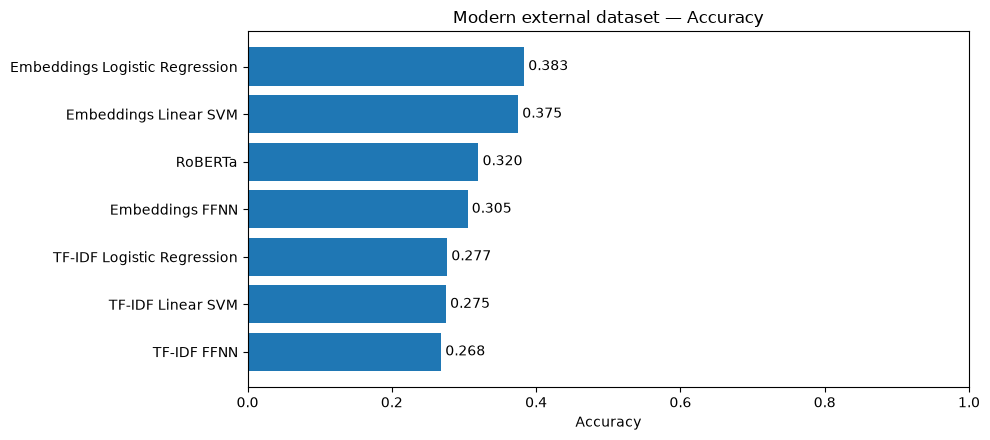

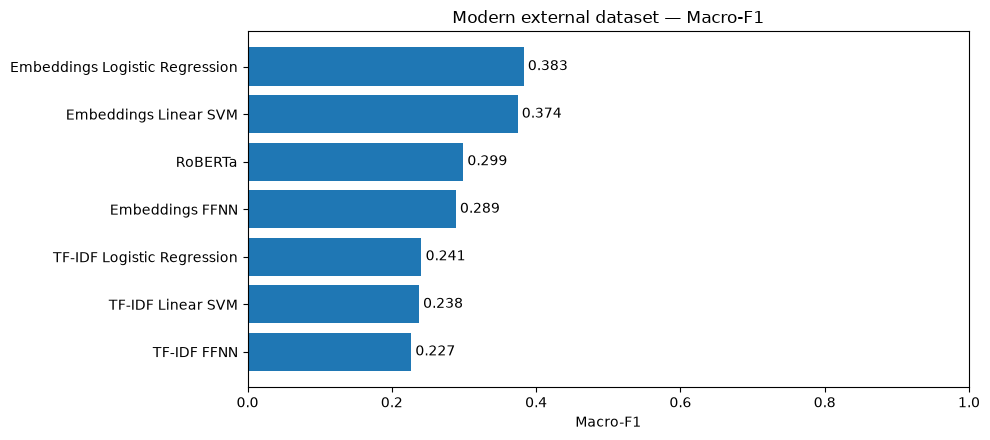

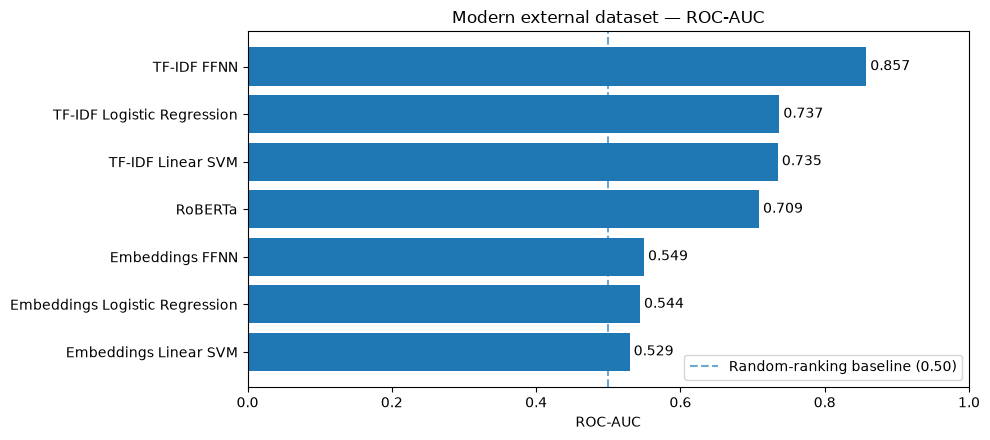

In [4]:
plot_metrics = [('accuracy', 'Accuracy'), ('macro_f1', 'Macro-F1'), ('roc_auc', 'ROC-AUC')]
for column, title in plot_metrics:
    ordered = metrics.sort_values(column, ascending=True)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bars = ax.barh(ordered['model'], ordered[column])
    ax.set_xlim(0, 1)
    ax.set_xlabel(title)
    ax.set_title(f'Modern external dataset — {title}')
    if column == 'roc_auc':
        ax.axvline(0.5, linestyle='--', alpha=0.65, label='Random-ranking baseline (0.50)')
        ax.legend(loc='lower right')
    ax.bar_label(bars, fmt='%.3f', padding=3)
    fig.tight_layout()
    plt.show()


## 5. Generator-specific AI recall and human false positives

For ChatGPT, Claude, and Gemini, the rate is **AI recall**. For human responses, the rate is **human false-positive rate** (lower is better). These are *different metrics* and should not be interpreted interchangeably.

generator,chatgpt,claude,gemini,human false-positive rate
model,,,,
Embeddings FFNN,0.1133,0.1533,0.0400,0.0867
Embeddings Linear SVM,0.2600,0.3200,0.1067,0.1867
Embeddings Logistic Regression,0.2933,0.3200,0.0933,0.1733
TF-IDF FFNN,0.0400,0.0333,0.0000,0.0000
TF-IDF Linear SVM,0.0133,0.0933,0.0000,0.0067
TF-IDF Logistic Regression,0.0267,0.0933,0.0000,0.0133
RoBERTa,0.0933,0.1867,0.0133,0.0133


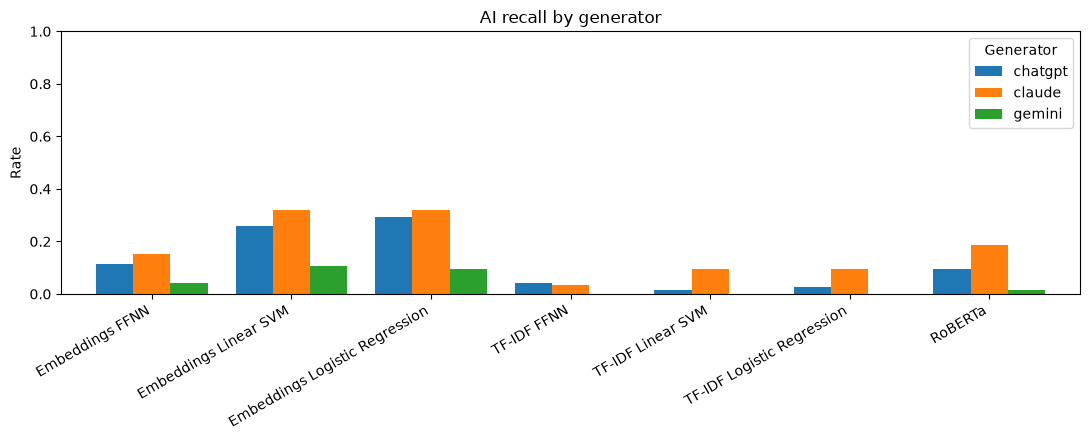

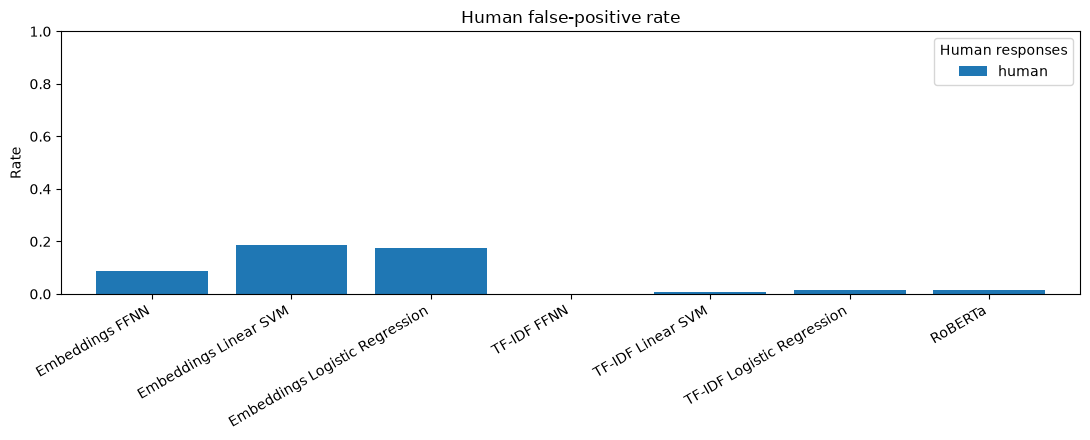

In [13]:
tfidf_gen = pd.read_csv(files['TF-IDF generator metrics'])
embedding_gen = pd.read_csv(files['Embeddings generator metrics'])
roberta_gen = pd.read_csv(files['RoBERTa generator metrics'])

gen = pd.concat([tfidf_gen, embedding_gen, roberta_gen], ignore_index=True)
expected_gen_cols = {'model', 'generator', 'n', 'metric', 'rate'}

assert expected_gen_cols.issubset(gen.columns), 'Missing generator-metric columns'
assert set(gen['model']) == set(metrics['model']), \
    'Generator CSVs do not contain all seven models'
assert ((gen.loc[gen.generator.str.lower() == 'human', 'metric'] ==
         'human_false_positive_rate').all()), 'Human rate must be false-positive rate'
assert ((gen.loc[gen.generator.str.lower() != 'human', 'metric'] ==
         'ai_recall').all()), 'AI generator rate must be recall'

rates = gen.pivot(index='model', columns='generator', values='rate').reindex(metrics['model'])
display(rates.rename(columns={'human': 'human false-positive rate'}).round(4))

for generators, title in [(['chatgpt', 'claude', 'gemini'], 'AI recall by generator'),
                          (['human'], 'Human false-positive rate')]:
    available = [c for c in generators if c in rates.columns]
    if not available:
        continue
    ax = rates[available].plot(kind='bar', figsize=(11, 4.5), width=0.8)
    ax.set_title(title)
    ax.set_ylabel('Rate')
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.legend(title='Generator' if generators[0] != 'human' else 'Human responses')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()


## 6. ROC curves — all seven trained models

Continuous scores are needed for these curves: probabilities for LR/FFNN, decision margins for Linear SVM. A margin does **not** represent a calibrated probability. We do not change any decision threshold here.

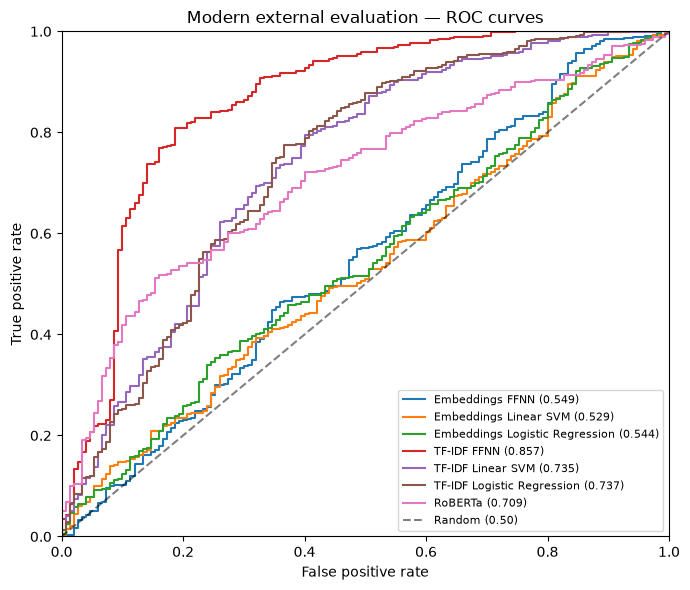

In [18]:
pred_files = [tfidf_pred, embedding_pred]
y_true = tfidf_pred['target'].to_numpy()
all_score_columns = {}
all_prediction_columns = {}
for df in pred_files:
    for col in df.columns:
        if col.endswith('_score'):
            name = col.removesuffix('_score')
            assert name not in all_score_columns, f'Duplicate score column: {name}'
            all_score_columns[name] = df[col].to_numpy(dtype=float)
        elif col.endswith('_prediction'):
            name = col.removesuffix('_prediction')
            assert name not in all_prediction_columns, f'Duplicate prediction column: {name}'
            all_prediction_columns[name] = df[col].to_numpy(dtype=int)

# Include RoBERTa in the ROC and confusion matrix comparisons
all_score_columns["roberta"] = roberta_pred["roberta_score"].to_numpy(dtype=float)
all_prediction_columns["roberta"] = roberta_pred["roberta_prediction"].to_numpy(dtype=int)

expected_keys = {name.lower().replace(' ', '_').replace('-', '_') for name in metrics['model']}

assert set(all_score_columns) == expected_keys, 'Missing or extra score columns'
assert set(all_prediction_columns) == expected_keys, 'Missing or extra prediction columns'

fig, ax = plt.subplots(figsize=(7, 6))
for name in metrics['model']:
    key = name.lower().replace(' ', '_').replace('-', '_')
    scores = all_score_columns[key]
    assert len(scores) == len(y_true) and np.isfinite(scores).all()
    observed_auc = roc_auc_score(y_true, scores)
    saved_auc = float(metrics.loc[metrics['model'] == name, 'roc_auc'].iloc[0])
    assert np.isclose(observed_auc, saved_auc, atol=1e-6),            f'{name}: ROC-AUC differs from exported metrics; rerun both evaluation exports'
    fpr, tpr, _ = roc_curve(y_true, scores)
    ax.plot(fpr, tpr, label=f'{name} ({observed_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (0.50)')
ax.set(xlabel='False positive rate', ylabel='True positive rate',
       title='Modern external evaluation — ROC curves', xlim=(0, 1), ylim=(0, 1))
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
plt.show()


## 7. Confusion matrices and per-class recall

Rows show the **actual** class; columns show the **predicted** class. Human = 0; AI = 1. These use the original predictions from the two evaluation notebooks, without any threshold changes.

Embeddings FFNN: human recall = 91.3%; AI recall = 10.2%
Embeddings Linear SVM: human recall = 81.3%; AI recall = 22.9%
Embeddings Logistic Regression: human recall = 82.7%; AI recall = 23.6%
TF-IDF FFNN: human recall = 100.0%; AI recall = 2.4%
TF-IDF Linear SVM: human recall = 99.3%; AI recall = 3.6%
TF-IDF Logistic Regression: human recall = 98.7%; AI recall = 4.0%
RoBERTa: human recall = 98.7%; AI recall = 9.8%


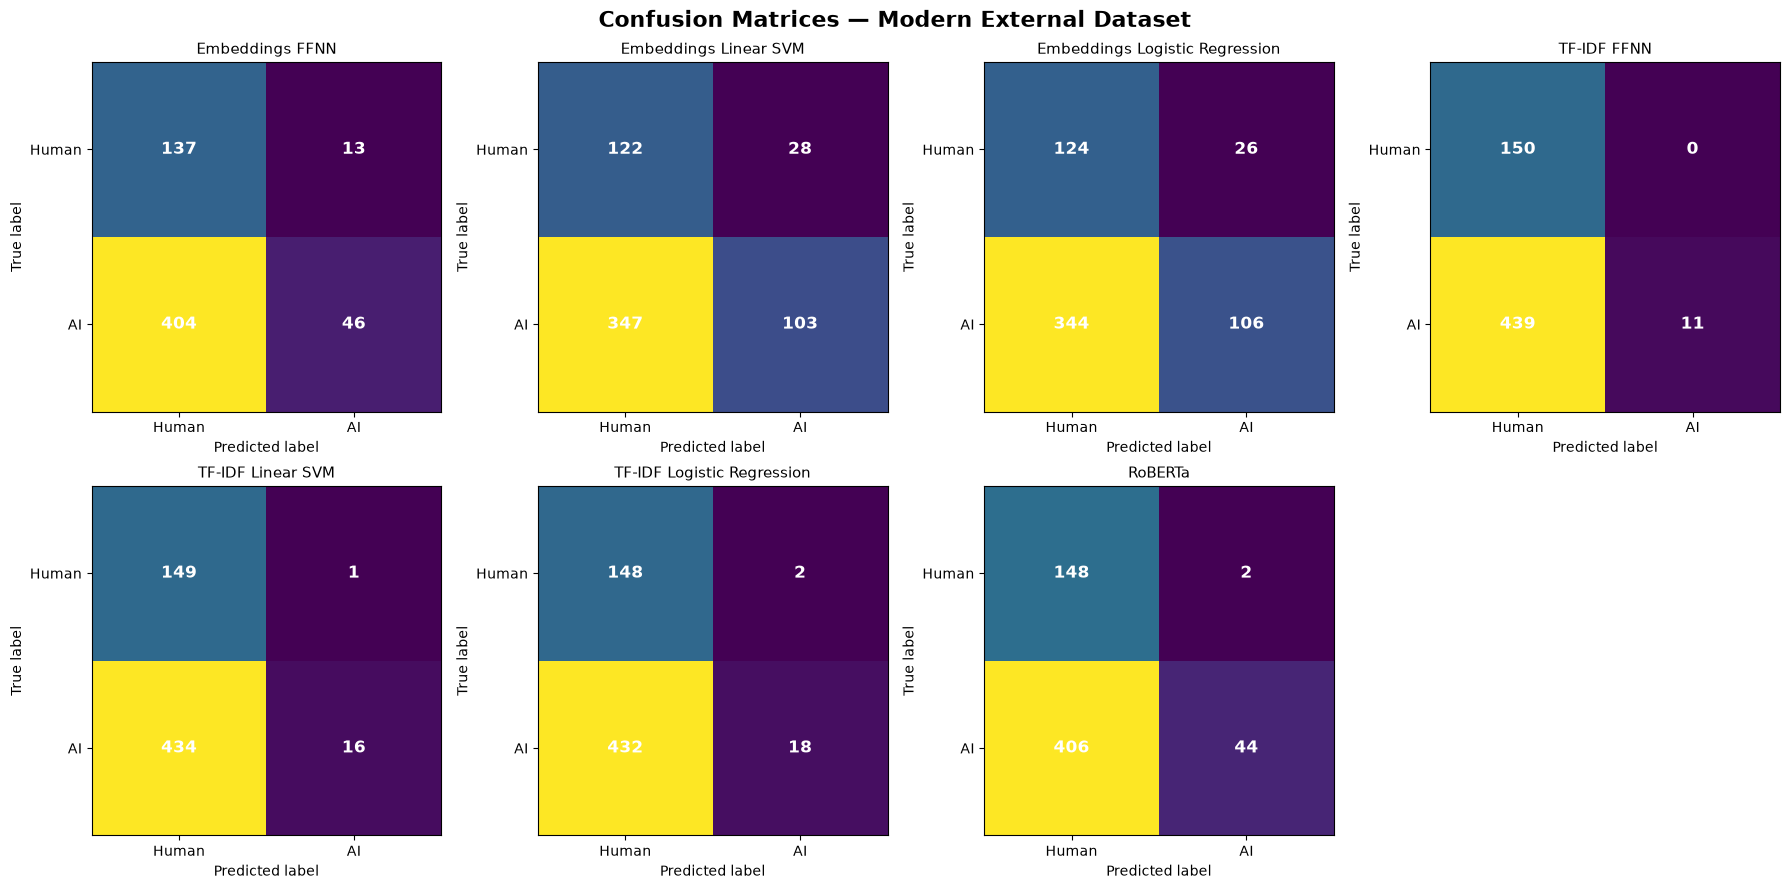

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, name in enumerate(metrics['model']):
    key = name.lower().replace(' ', '_').replace('-', '_')
    pred = all_prediction_columns[key]

    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    human_recall = cm[0, 0] / cm[0].sum()
    ai_recall = cm[1, 1] / cm[1].sum()

    print(f'{name}: human recall = {human_recall:.1%}; AI recall = {ai_recall:.1%}')

    ax = axes[i]

    disp = ConfusionMatrixDisplay(cm, display_labels=['Human', 'AI'])
    disp.plot(ax=ax, colorbar=False, values_format='d')

    # Improve annotation readability
    for text in disp.text_.ravel():
        text.set_color('white')
        text.set_fontsize(12)
        text.set_fontweight('bold')

    ax.set_title(name, fontsize=11)

# Hide the unused 8th subplot
for ax in axes[len(metrics):]:
    ax.axis('off')

fig.suptitle(
    'Confusion Matrices — Modern External Dataset',
    fontsize=16,
    fontweight='bold'
)

fig.tight_layout()
plt.show()


## RoBERTa: Human vs. AI prediction score distributions

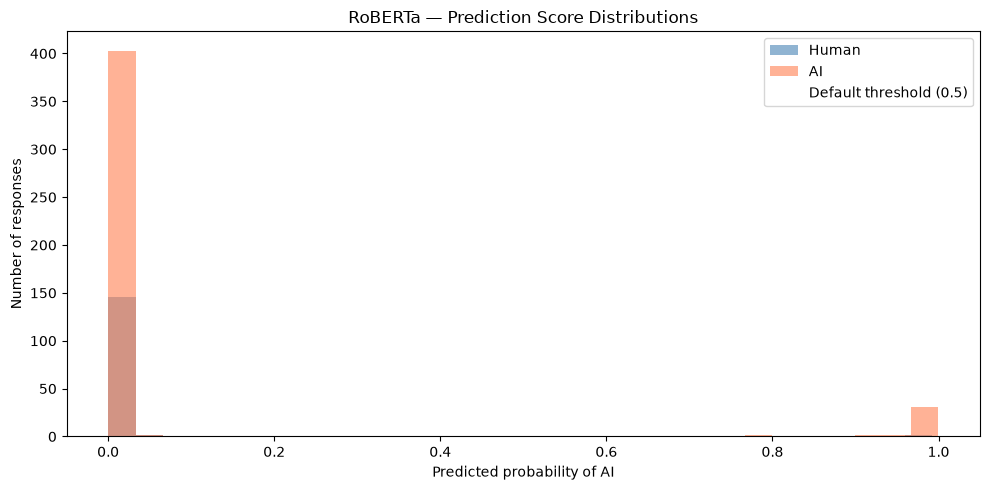

Human median score: 0.0
AI median score: 0.0001


In [23]:
human_scores = roberta_pred.loc[
    roberta_pred["target"] == 0, "roberta_score"
]

ai_scores = roberta_pred.loc[
    roberta_pred["target"] == 1, "roberta_score"
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    human_scores,
    bins=30,
    alpha=0.6,
    label="Human",
    color="steelblue"
)

ax.hist(
    ai_scores,
    bins=30,
    alpha=0.6,
    label="AI",
    color="coral"
)

ax.axvline(
    0.5,
    color="white",
    linestyle="--",
    linewidth=2,
    label="Default threshold (0.5)"
)

ax.set_title("RoBERTa — Prediction Score Distributions")
ax.set_xlabel("Predicted probability of AI")
ax.set_ylabel("Number of responses")
ax.legend()

plt.tight_layout()
plt.show()

print("Human median score:", round(human_scores.median(), 4))
print("AI median score:", round(ai_scores.median(), 4))


## Experiment: Modern ChatGPT vs. Human only

### RoBERTa

Dataset composition:
model
human      150
chatgpt    150
Name: count, dtype: int64

RoBERTa — Modern ChatGPT Only
Accuracy: 0.54
Macro F1: 0.4254
ROC-AUC: 0.8073
Human recall: 98.7%
ChatGPT recall: 9.3%


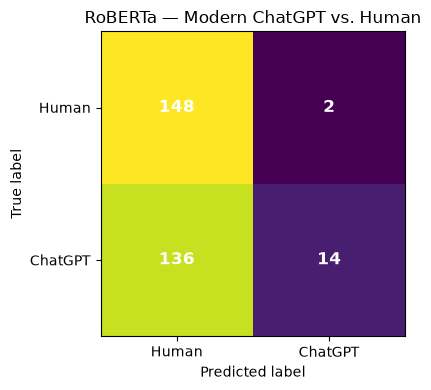

In [27]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

chatgpt_subset = roberta_pred[
    roberta_pred["model"].str.lower().isin(["human", "chatgpt"])
].copy()

y_chatgpt = chatgpt_subset["target"]
pred_chatgpt = chatgpt_subset["roberta_prediction"]
score_chatgpt = chatgpt_subset["roberta_score"]

print("Dataset composition:")
print(chatgpt_subset["model"].value_counts())

print("\nRoBERTa — Modern ChatGPT Only")
print("Accuracy:", round(accuracy_score(y_chatgpt, pred_chatgpt), 4))
print("Macro F1:", round(f1_score(y_chatgpt, pred_chatgpt, average="macro"), 4))
print("ROC-AUC:", round(roc_auc_score(y_chatgpt, score_chatgpt), 4))

cm = confusion_matrix(y_chatgpt, pred_chatgpt, labels=[0, 1])

print("Human recall:", f"{cm[0, 0] / cm[0].sum():.1%}")
print("ChatGPT recall:", f"{cm[1, 1] / cm[1].sum():.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(cm, display_labels=["Human", "ChatGPT"])
disp.plot(ax=ax, colorbar=False, values_format="d")
for text in disp.text_.ravel():
    text.set_color("white")
    text.set_fontsize(12)
    text.set_fontweight("bold")
ax.set_title("RoBERTa — Modern ChatGPT vs. Human")
plt.tight_layout()
plt.show()


## Experiment: Modern ChatGPT vs. Human — All 7 Models

In [28]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Keep only human and ChatGPT responses
subset_mask = (
    roberta_pred["model"].str.lower().isin(["human", "chatgpt"])
).to_numpy()

y_subset = y_true[subset_mask]

results_chatgpt = []

for name in metrics["model"]:
    key = name.lower().replace(" ", "_").replace("-", "_")

    # Use existing scores and predictions
    scores = all_score_columns[key][subset_mask]
    predictions = all_prediction_columns[key][subset_mask]

    cm = confusion_matrix(y_subset, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    results_chatgpt.append({
        "model": name,
        "accuracy": accuracy_score(y_subset, predictions),
        "macro_f1": f1_score(
            y_subset, predictions, average="macro"
        ),
        "roc_auc": roc_auc_score(y_subset, scores),
        "human_recall": tn / (tn + fp),
        "ai_recall": tp / (tp + fn),
        "human_fpr": fp / (tn + fp)
    })

chatgpt_comparison = pd.DataFrame(results_chatgpt)

print("Modern ChatGPT vs. Human — 300 Responses")
display(
    chatgpt_comparison.style.format({
        "accuracy": "{:.1%}",
        "macro_f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "human_recall": "{:.1%}",
        "ai_recall": "{:.1%}",
        "human_fpr": "{:.1%}"
    })
)


Modern ChatGPT vs. Human — 300 Responses


,model,accuracy,macro_f1,roc_auc,human_recall,ai_recall,human_fpr
0,Embeddings FFNN,51.3%,0.4206,0.6075,91.3%,11.3%,8.7%
1,Embeddings Linear SVM,53.7%,0.4983,0.5670,81.3%,26.0%,18.7%
2,Embeddings Logistic Regression,56.0%,0.5263,0.5969,82.7%,29.3%,17.3%
3,TF-IDF FFNN,52.0%,0.3763,0.8981,100.0%,4.0%,0.0%
4,TF-IDF Linear SVM,50.3%,0.3464,0.7531,99.3%,1.3%,0.7%
5,TF-IDF Logistic Regression,50.7%,0.3590,0.7621,98.7%,2.7%,1.3%
6,RoBERTa,54.0%,0.4254,0.8073,98.7%,9.3%,1.3%


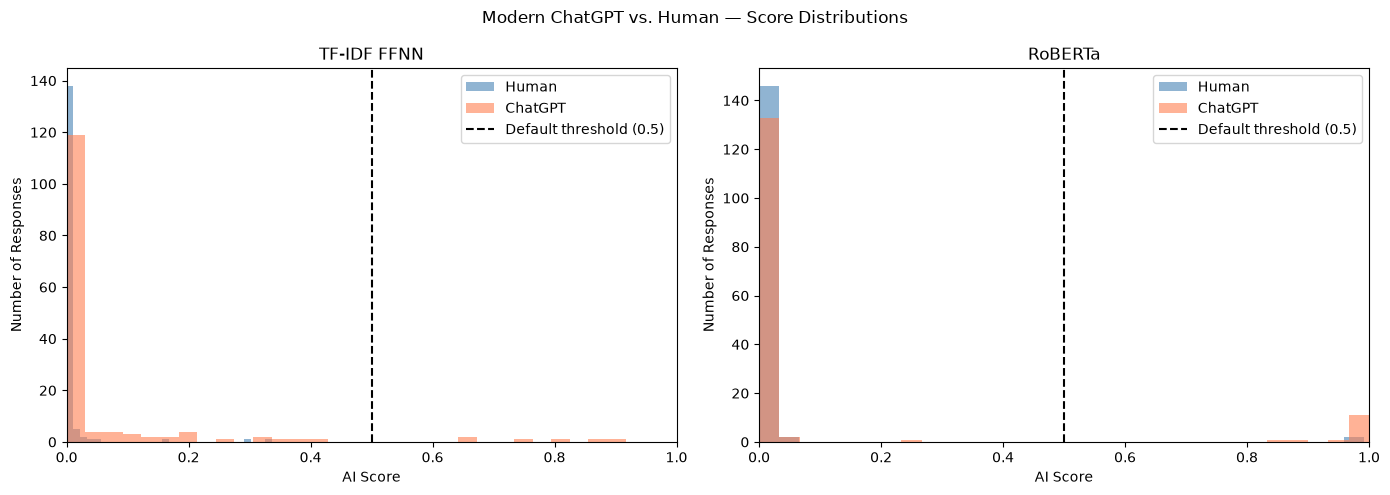

In [29]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, key) in zip(axes, [
    ("TF-IDF FFNN", "tf_idf_ffnn"),
    ("RoBERTa", "roberta")
]):
    scores = np.asarray(all_score_columns[key])[subset_mask]

    ax.hist(scores[y_subset == 0], bins=30, alpha=0.6,
            label="Human", color="steelblue")
    ax.hist(scores[y_subset == 1], bins=30, alpha=0.6,
            label="ChatGPT", color="coral")

    ax.axvline(0.5, color="black", linestyle="--",
               label="Default threshold (0.5)")

    ax.set_title(name)
    ax.set_xlabel("AI Score")
    ax.set_ylabel("Number of Responses")
    ax.set_xlim(0, 1)
    ax.legend()

plt.suptitle("Modern ChatGPT vs. Human — Score Distributions")
plt.tight_layout()
plt.show()

## Compare score distributions on a logarithmic scale

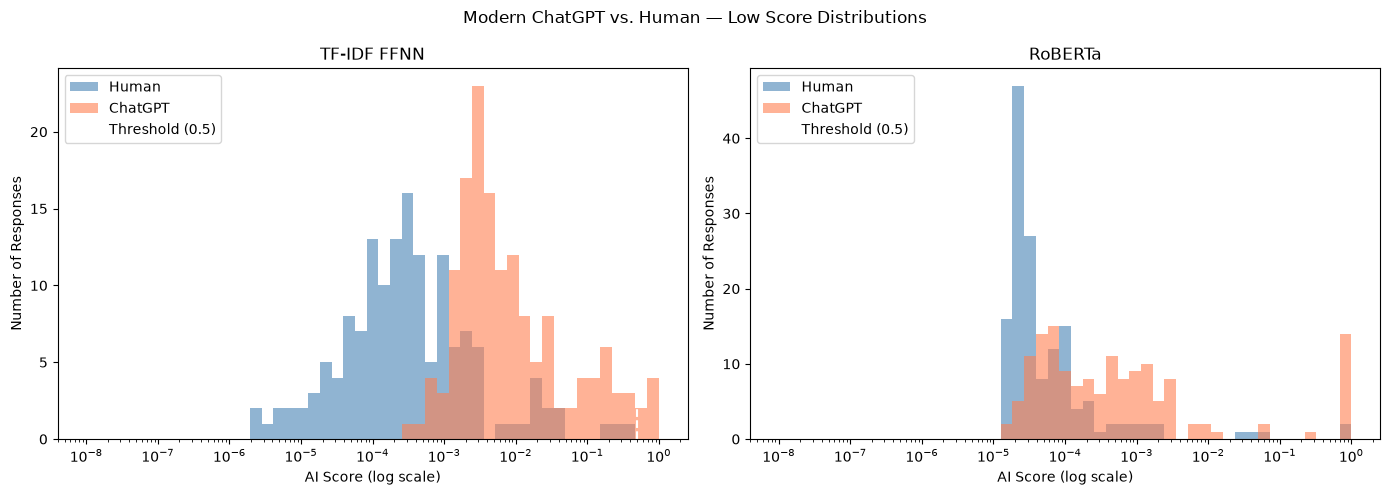

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, key) in zip(axes, [
    ("TF-IDF FFNN", "tf_idf_ffnn"),
    ("RoBERTa", "roberta")
]):
    scores = np.asarray(all_score_columns[key])[subset_mask]

    human_scores = scores[y_subset == 0]
    chatgpt_scores = scores[y_subset == 1]

    bins = np.logspace(-8, 0, 50)

    ax.hist(np.clip(human_scores, 1e-8, 1),
            bins=bins, alpha=0.6,
            label="Human", color="steelblue")

    ax.hist(np.clip(chatgpt_scores, 1e-8, 1),
            bins=bins, alpha=0.6,
            label="ChatGPT", color="coral")

    ax.axvline(0.5, color="white", linestyle="--",
               label="Threshold (0.5)")

    ax.set_xscale("log")
    ax.set_title(name)
    ax.set_xlabel("AI Score (log scale)")
    ax.set_ylabel("Number of Responses")
    ax.legend()

plt.suptitle("Modern ChatGPT vs. Human — Low Score Distributions")
plt.tight_layout()
plt.show()

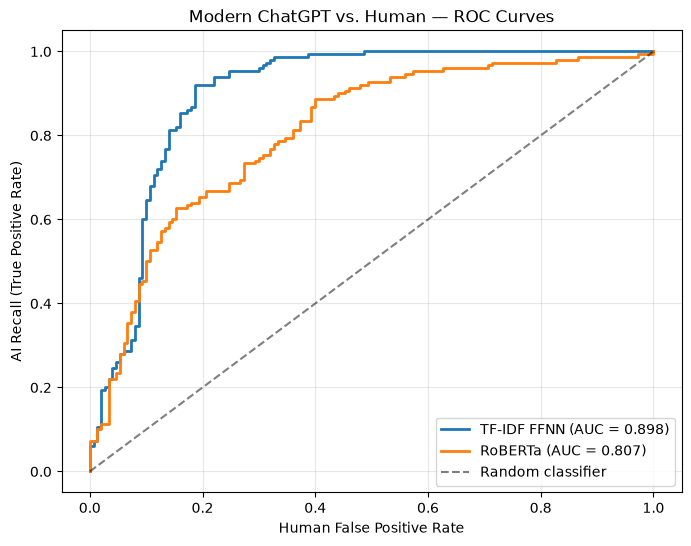

In [32]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

for name, key in [
    ("TF-IDF FFNN", "tf_idf_ffnn"),
    ("RoBERTa", "roberta")
]:
    scores = np.asarray(all_score_columns[key])[subset_mask]

    fpr, tpr, thresholds = roc_curve(y_subset, scores)
    auc = roc_auc_score(y_subset, scores)

    plt.plot(fpr, tpr, linewidth=2,
             label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5,
         label="Random classifier")

plt.xlabel("Human False Positive Rate")
plt.ylabel("AI Recall (True Positive Rate)")
plt.title("Modern ChatGPT vs. Human — ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Calculate the thresholds corresponding to a maximum 5% and 10% human false-positive rate

In [33]:
from sklearn.metrics import roc_curve
import numpy as np
import pandas as pd

results = []

for name, key in [
    ("TF-IDF FFNN", "tf_idf_ffnn"),
    ("RoBERTa", "roberta")
]:
    scores = np.asarray(all_score_columns[key])[subset_mask]
    fpr, tpr, thresholds = roc_curve(
        y_subset, scores, drop_intermediate=False
    )

    for max_fpr in [0.05, 0.10]:
        eligible = np.where(fpr <= max_fpr)[0]
        idx = eligible[np.argmax(tpr[eligible])]

        results.append({
            "model": name,
            "max_human_fpr": max_fpr,
            "threshold": thresholds[idx],
            "ai_recall": tpr[idx],
            "human_fpr": fpr[idx]
        })

threshold_comparison = pd.DataFrame(results)

display(
    threshold_comparison.style.format({
        "max_human_fpr": "{:.0%}",
        "threshold": "{:.8f}",
        "ai_recall": "{:.1%}",
        "human_fpr": "{:.1%}"
    })
)

,model,max_human_fpr,threshold,ai_recall,human_fpr
0,TF-IDF FFNN,5%,0.02242509,26.0%,4.7%
1,TF-IDF FFNN,10%,0.00309986,64.7%,10.0%
2,RoBERTa,5%,0.00182704,23.3%,4.7%
3,RoBERTa,10%,0.00033405,50.0%,10.0%


## 8. Export one combined results table

These files are derived only from the saved external evaluation exports. Do not use this same external test set repeatedly to select thresholds or tune models.

In [22]:
metrics.to_csv(RESULTS_DIR / 'modern_seven_model_comparison.csv', index=False)
gen.to_csv(RESULTS_DIR / 'modern_seven_model_generator_metrics.csv', index=False)
print('Saved:')
print(RESULTS_DIR / 'modern_seven_model_comparison.csv')
print(RESULTS_DIR / 'modern_seven_model_generator_metrics.csv')


Saved:
/Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation/modern_seven_model_comparison.csv
/Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation/modern_seven_model_generator_metrics.csv
